# Stage 2: Fine-tuning and evaluation

Fine-tune the pretrained LSTM on personal text, and evaluate it fairly.

1. **Evaluate:** 5-fold cross-validation over personal sentences. Every fold compares four models on exactly the same held-out words:
   - `bigram`: interpolated bigram trained on the fold's training sentences
   - `lstm_scratch`: small LSTM trained only on the personal sentences
   - `pretrained_only`: the WikiText-2 model, no personal data (zero-shot)
   - `pretrained_ft`: the WikiText-2 model fine-tuned on the personal sentences
2. **Ship:** fine-tune the pretrained model on all personal sentences for the keyboard app.

Run `pretrain.ipynb` first (or use the pretrained model already in `artifacts/`). Run this notebook from the project root. It takes about 12 minutes on CPU.

In [1]:
import copy
import json
import math
import random
import statistics
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from nextword.model import (LSTM, PAD, PAD_IDX, UNK, UNK_IDX, Predictor, build_vocab,
                            expand_vocab, make_examples, split_sentences, text_to_indices)

ROOT = Path.cwd()
CORPUS = ROOT / 'data' / 'corpus.txt'
PRETRAINED = ROOT / 'artifacts' / 'pretrained_lstm.pt'
CHECKPOINT = ROOT / 'artifacts' / 'lstm_next_word.pt'
REPORTS = ROOT / 'reports'

SEED = 42
SEQ_LEN = 30
BATCH_SIZE = 64
MAX_EPOCHS = 150
PATIENCE = 10
K_FOLDS = 5
VAL_FRACTION = 0.1

# from-scratch baseline: small + heavily regularized, picked with a validation sweep
SCRATCH_CONFIG = dict(embed_dim=128, hidden_dim=128, num_layers=1, dropout=0.5)
SCRATCH_LR, SCRATCH_WD = 0.002, 1e-4
# fine-tuning: lower learning rate so the pretrained knowledge is adapted, not overwritten
FINETUNE_LR, FINETUNE_WD, FINETUNE_DROPOUT = 0.001, 0.0, 0.5
# The shipped keyboard should know *my* sentences, not just generalize to unseen ones.
# CV early stopping peaks at ~18 epochs (best on unseen text), but at that point the model
# only gets 57% of my own next words right and greedy replies loop on frequent phrases.
# At 70 epochs it gets 92% and replies stay coherent, so the app model trains longer.
FINAL_EPOCHS = 70

MODELS = ['bigram', 'lstm_scratch', 'pretrained_only', 'pretrained_ft']
LABELS = {'bigram': 'Bigram baseline', 'lstm_scratch': 'LSTM, personal data only',
          'pretrained_only': 'Pretrained, no fine-tuning', 'pretrained_ft': 'Pretrained + fine-tuned'}
SAMPLES = ['I love to', 'I love to play', 'I love to visit the', 'In my free time I',
           'Snooker is a game of', 'Hiking clears my', 'I built a diabetes risk', 'I am currently learning']

## 1. Training helpers

Every prefix of every sentence becomes one (context → next word) example. `fit` trains on those examples, with early stopping when a validation set is given. `finetune` extends the pretrained vocabulary with personal words and fine-tunes at a lower learning rate.

In [2]:
def fit(model, X_train, y_train, lr, weight_decay, X_val=None, y_val=None, epochs=MAX_EPOCHS):
    """Train on (context -> next word) examples. With a validation set: early stopping."""
    criterion = nn.CrossEntropyLoss()
    val_criterion = nn.CrossEntropyLoss(ignore_index=UNK_IDX)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
    history = {'train_loss': [], 'val_loss': []}
    best = {'loss': float('inf'), 'epoch': epochs, 'state': None}

    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for batch_x, batch_y in loader:
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total += loss.item() * len(batch_y)
        history['train_loss'].append(total / len(y_train))
        if X_val is None:
            continue

        model.eval()
        with torch.no_grad():
            val_loss = val_criterion(model(X_val), y_val).item()
        history['val_loss'].append(val_loss)
        if val_loss < best['loss']:
            best = {'loss': val_loss, 'epoch': epoch, 'state': copy.deepcopy(model.state_dict())}
        if epoch - best['epoch'] >= PATIENCE:
            break

    if best['state'] is not None:
        model.load_state_dict(best['state'])
    return model, best['epoch'], history


def load_pretrained():
    if not PRETRAINED.exists():
        raise FileNotFoundError('No pretrained model found. Run pretrain.ipynb first.')
    ckpt = torch.load(PRETRAINED, map_location='cpu')
    model = LSTM(len(ckpt['vocab']), **ckpt['model_config'])
    model.load_state_dict(ckpt['state_dict'])
    return model, ckpt['vocab'], ckpt['model_config']


def extend_vocab(base_vocab, sentences):
    """General vocabulary + any personal words it does not have yet."""
    vocab = dict(base_vocab)
    for word in build_vocab(sentences):
        vocab.setdefault(word, len(vocab))
    return vocab


def finetune(pre_model, pre_vocab, pre_config, train_s, val_s=None, epochs=MAX_EPOCHS):
    vocab = extend_vocab(pre_vocab, train_s)
    model = expand_vocab(pre_model, pre_vocab, vocab, pre_config)
    model.dropout.p = FINETUNE_DROPOUT
    X, y = make_examples(train_s, vocab, SEQ_LEN)
    val = make_examples(val_s, vocab, SEQ_LEN) if val_s else (None, None)
    model, best_epoch, history = fit(model, X, y, FINETUNE_LR, FINETUNE_WD, *val, epochs=epochs)
    return model, vocab, best_epoch, history

## 2. Evaluation helpers

Every model returns, for each test word, its top-3 guesses and the log-probability it gave the true word (`None` if the word is not in that model's vocabulary).

- **Top-k accuracy** is measured over *every* test word. A word a model can't produce counts as a miss, so all models share the same denominator.
- **Perplexity** is measured over the words every model knows, so the numbers are directly comparable.

In [3]:
@torch.no_grad()
def lstm_predictions(model, vocab, sentences):
    model.eval()
    X, _ = make_examples(sentences, vocab, SEQ_LEN)
    logits = torch.cat([model(xb) for xb in X.split(512)])
    return from_scores(logits, torch.log_softmax(logits, 1), vocab, sentences)


def bigram_predictions(train_s, test_s, vocab, lam=0.7):
    """Interpolated bigram: P(w | prev) = lam * P_bigram + (1 - lam) * P_unigram (add-one)."""
    V, BOS = len(vocab), len(vocab)                        # extra row for "start of sentence"
    pair, uni = torch.zeros(V + 1, V), torch.ones(V)
    for tokens in train_s:
        idx = text_to_indices(tokens, vocab)
        for i, t in enumerate(idx):
            pair[idx[i - 1] if i else BOS, t] += 1
            uni[t] += 1
    p_uni = uni / uni.sum()
    row = pair.sum(1, keepdim=True)
    probs = lam * torch.where(row > 0, pair / row.clamp(min=1), p_uni) + (1 - lam) * p_uni
    prev = []
    for tokens in test_s:
        idx = text_to_indices(tokens, vocab)
        prev += [idx[i - 1] if i else BOS for i in range(len(idx))]
    p = probs[torch.tensor(prev)]
    return from_scores(p, p.log(), vocab, test_s)


def from_scores(scores, log_probs, vocab, sentences):
    idx_to_word = {i: w for w, i in vocab.items()}
    scores = scores.clone()
    scores[:, [PAD_IDX, UNK_IDX]] = -float('inf')          # never suggest these
    top = scores.topk(3, dim=1).indices.tolist()
    words = [t for s in sentences for t in s]
    out = []
    for row, (guesses, word) in enumerate(zip(top, words)):
        logp = log_probs[row, vocab[word]].item() if word in vocab else None
        out.append({'top3': [idx_to_word[g] for g in guesses], 'logp': logp})
    return out


def score(predictions, words, common):
    """Top-k accuracy over ALL test words (a word the model can't produce is a miss);
    perplexity over the words every compared model knows, so the numbers are comparable."""
    top1 = statistics.mean(p['top3'][0] == w for p, w in zip(predictions, words))
    top3 = statistics.mean(w in p['top3'] for p, w in zip(predictions, words))
    logps = [p['logp'] for p, w in zip(predictions, words) if w in common]
    coverage = statistics.mean(p['logp'] is not None for p in predictions)
    return {'perplexity': math.exp(-statistics.mean(logps)), 'top1_acc': top1, 'top3_acc': top3,
            'vocab_coverage': coverage}

## 3. Cross-validation

In each fold the vocabulary comes from the training sentences only, and all four models are scored on the same held-out words.

In [4]:
def cross_validate(sentences, pre_model, pre_vocab, pre_config):
    order = list(range(len(sentences)))
    random.Random(SEED).shuffle(order)
    folds = [order[i::K_FOLDS] for i in range(K_FOLDS)]
    results, curves = [], {'lstm_scratch': [], 'pretrained_ft': []}

    for k, test_idx in enumerate(folds, 1):
        held_out = set(test_idx)
        rest = [i for i in order if i not in held_out]
        n_val = max(1, int(len(rest) * VAL_FRACTION))
        val_s = [sentences[i] for i in rest[:n_val]]
        train_s = [sentences[i] for i in rest[n_val:]]
        test_s = [sentences[i] for i in test_idx]
        words = [t for s in test_s for t in s]

        personal_vocab = build_vocab(train_s)               # vocab from training data only
        torch.manual_seed(SEED + k)
        scratch = LSTM(len(personal_vocab), **SCRATCH_CONFIG)
        X_tr, y_tr = make_examples(train_s, personal_vocab, SEQ_LEN)
        X_va, y_va = make_examples(val_s, personal_vocab, SEQ_LEN)
        scratch, scratch_epoch, scratch_hist = fit(scratch, X_tr, y_tr, SCRATCH_LR, SCRATCH_WD, X_va, y_va)

        torch.manual_seed(SEED + k)
        ft, ft_vocab, ft_epoch, ft_hist = finetune(pre_model, pre_vocab, pre_config, train_s, val_s)

        preds = {
            'bigram': bigram_predictions(train_s, test_s, personal_vocab),
            'lstm_scratch': lstm_predictions(scratch, personal_vocab, test_s),
            'pretrained_only': lstm_predictions(pre_model, pre_vocab, test_s),
            'pretrained_ft': lstm_predictions(ft, ft_vocab, test_s),
        }
        common = (set(personal_vocab) & set(pre_vocab) & set(ft_vocab)) - {PAD, UNK}
        fold = {'fold': k, 'test_words': len(words), 'best_epoch': {'lstm_scratch': scratch_epoch, 'pretrained_ft': ft_epoch}}
        fold.update({m: score(preds[m], words, common) for m in MODELS})
        results.append(fold)
        curves['lstm_scratch'].append(scratch_hist)
        curves['pretrained_ft'].append(ft_hist)
        print(f'Fold {k}: ' + ' | '.join(f'{m} top3 {fold[m]["top3_acc"]:.1%} ppl {fold[m]["perplexity"]:.0f}'
                                         for m in MODELS), flush=True)
    return results, curves


def summarize(results):
    summary = {}
    for m in MODELS:
        summary[m] = {metric: {'mean': round(statistics.mean(r[m][metric] for r in results), 4),
                               'std': round(statistics.stdev(r[m][metric] for r in results), 4)}
                      for metric in ('perplexity', 'top1_acc', 'top3_acc', 'vocab_coverage')}
    return summary

In [5]:
random.seed(SEED)
torch.manual_seed(SEED)
sentences = split_sentences(CORPUS.read_text(encoding='utf-8'))
pre_model, pre_vocab, pre_config = load_pretrained()
print(f'{len(sentences)} personal sentences, {sum(map(len, sentences))} tokens | '
      f'pretrained vocab {len(pre_vocab):,}')

99 personal sentences, 1856 tokens | pretrained vocab 12,000


In [6]:
print(f'== {K_FOLDS}-fold cross-validation ==')
results, curves = cross_validate(sentences, pre_model, pre_vocab, pre_config)
summary = summarize(results)

== 5-fold cross-validation ==


Fold 1: bigram top3 23.4% ppl 88 | lstm_scratch top3 22.9% ppl 92 | pretrained_only top3 16.7% ppl 446 | pretrained_ft top3 29.2% ppl 77


Fold 2: bigram top3 30.7% ppl 71 | lstm_scratch top3 28.1% ppl 90 | pretrained_only top3 16.2% ppl 534 | pretrained_ft top3 30.7% ppl 82


Fold 3: bigram top3 25.6% ppl 103 | lstm_scratch top3 25.1% ppl 94 | pretrained_only top3 15.6% ppl 470 | pretrained_ft top3 27.3% ppl 97


Fold 4: bigram top3 27.2% ppl 67 | lstm_scratch top3 24.9% ppl 63 | pretrained_only top3 14.9% ppl 443 | pretrained_ft top3 31.5% ppl 51


Fold 5: bigram top3 24.9% ppl 94 | lstm_scratch top3 23.9% ppl 97 | pretrained_only top3 14.0% ppl 534 | pretrained_ft top3 28.3% ppl 88


## 4. Results

In [7]:
table = pd.DataFrame({
    LABELS[m]: {
        'Top-3 accuracy': f'{s["top3_acc"]["mean"]:.1%} ± {s["top3_acc"]["std"] * 100:.1f}',
        'Top-1 accuracy': f'{s["top1_acc"]["mean"]:.1%} ± {s["top1_acc"]["std"] * 100:.1f}',
        'Perplexity': f'{s["perplexity"]["mean"]:.1f} ± {s["perplexity"]["std"]:.1f}',
        'Knows the word': f'{s["vocab_coverage"]["mean"]:.1%}',
    } for m, s in ((m, summary[m]) for m in MODELS[::-1])
}).T
table

,Top-3 accuracy,Top-1 accuracy,Perplexity,Knows the word
Pretrained + fine-tuned,29.4% ± 1.7,18.6% ± 2.4,78.9 ± 17.4,90.5%
"Pretrained, no fine-tuning",15.5% ± 1.1,7.5% ± 0.4,485.3 ± 45.7,79.3%
"LSTM, personal data only",25.0% ± 1.9,16.1% ± 1.7,87.2 ± 13.8,72.7%
Bigram baseline,26.4% ± 2.8,16.2% ± 1.9,84.6 ± 15.3,72.7%


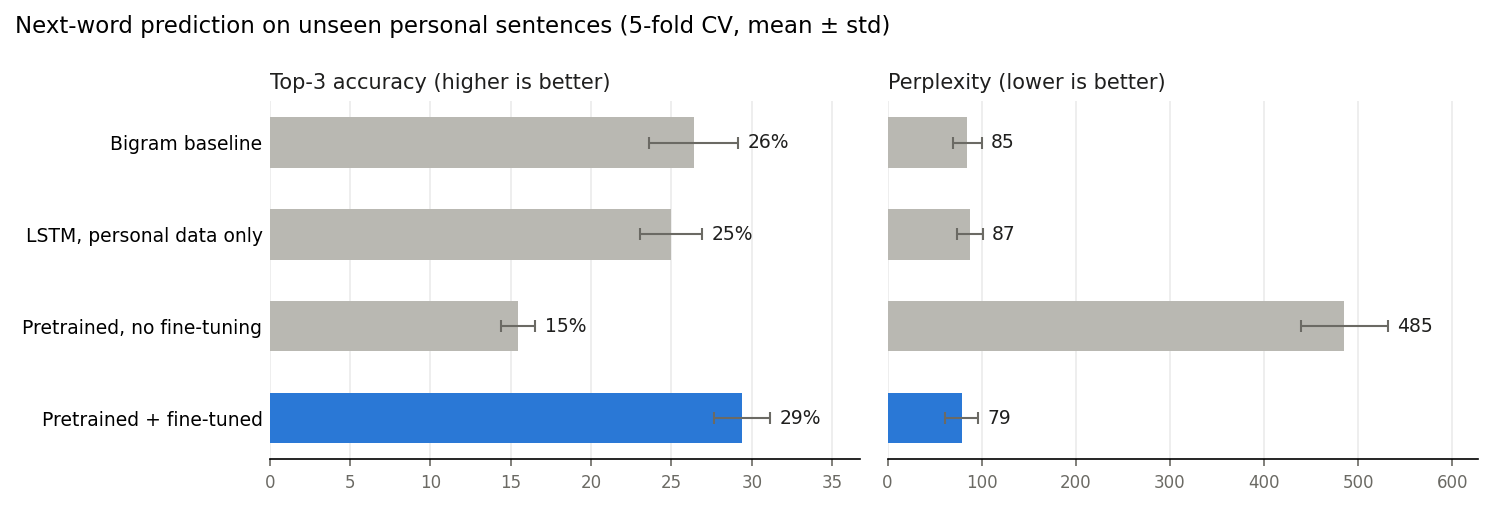

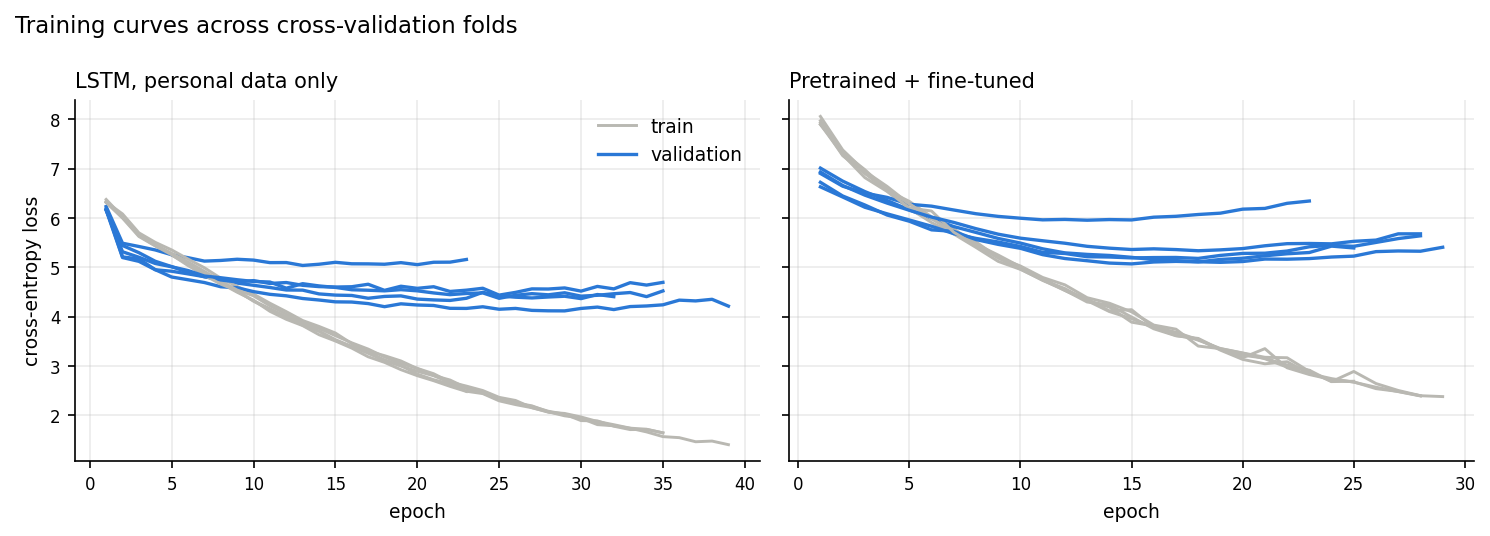

In [8]:
def plot_comparison(summary, path):
    order = MODELS[::-1]                                    # final model on top
    labels = [LABELS[m] for m in order]
    colors = ['#2a78d6' if m == 'pretrained_ft' else '#b9b8b2' for m in order]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), dpi=150)
    panels = [('top3_acc', 'Top-3 accuracy (higher is better)', 100, '{:.0f}%'),
              ('perplexity', 'Perplexity (lower is better)', 1, '{:.0f}')]
    for ax, (metric, title, scale, fmt) in zip(axes, panels):
        means = [summary[m][metric]['mean'] * scale for m in order]
        stds = [summary[m][metric]['std'] * scale for m in order]
        ax.barh(labels, means, xerr=stds, color=colors, height=0.55,
                error_kw=dict(ecolor='#6b6a64', elinewidth=1, capsize=3))
        for y, (v, s) in enumerate(zip(means, stds)):
            ax.text(v + s + max(means) * 0.02, y, fmt.format(v), va='center', fontsize=9, color='#1f1f1e')
        ax.set_title(title, fontsize=10, loc='left', color='#1f1f1e')
        ax.set_xlim(0, max(m + s for m, s in zip(means, stds)) * 1.18)
        ax.spines[['top', 'right', 'left']].set_visible(False)
        ax.tick_params(axis='y', length=0, labelsize=9)
        ax.tick_params(axis='x', labelsize=8, colors='#6b6a64')
        ax.grid(axis='x', alpha=0.25)
        ax.set_axisbelow(True)
    axes[1].set_yticklabels([])
    fig.suptitle(f'Next-word prediction on unseen personal sentences ({K_FOLDS}-fold CV, mean ± std)',
                 fontsize=11, x=0.01, ha='left')
    fig.tight_layout()
    fig.savefig(path)
    plt.show()


def plot_curves(curves, path):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), dpi=150, sharey=True)
    for ax, (name, title) in zip(axes, [('lstm_scratch', 'LSTM, personal data only'),
                                         ('pretrained_ft', 'Pretrained + fine-tuned')]):
        for i, h in enumerate(curves[name]):
            epochs = range(1, len(h['train_loss']) + 1)
            ax.plot(epochs, h['train_loss'], color='#b9b8b2', lw=1.4, label='train' if i == 0 else None)
            ax.plot(epochs, h['val_loss'], color='#2a78d6', lw=1.6, label='validation' if i == 0 else None)
        ax.set_title(title, fontsize=10, loc='left')
        ax.set_xlabel('epoch', fontsize=9)
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(alpha=0.25)
        ax.tick_params(labelsize=8)
    axes[0].set_ylabel('cross-entropy loss', fontsize=9)
    axes[0].legend(frameon=False, fontsize=9)
    fig.suptitle('Training curves across cross-validation folds', fontsize=11, x=0.01, ha='left')
    fig.tight_layout()
    fig.savefig(path)
    plt.show()


REPORTS.mkdir(exist_ok=True)
plot_comparison(summary, REPORTS / 'model_comparison.png')
plot_curves(curves, REPORTS / 'loss_curve.png')

## 5. Final model for the keyboard app

Fine-tune on all personal sentences for `FINAL_EPOCHS` epochs. Cross-validation finds the best epoch for *unseen* text (~18), but the app should know my own sentences well and avoid looping replies, so it trains longer.

In [9]:
cv_best = round(statistics.median(r['best_epoch']['pretrained_ft'] for r in results))
final_epochs = FINAL_EPOCHS
print(f'== Final model: fine-tune on all {len(sentences)} sentences for {final_epochs} epochs '
      f'(CV best for unseen text: {cv_best}) ==')
torch.manual_seed(SEED)
model, vocab, _, _ = finetune(pre_model, pre_vocab, pre_config, sentences, epochs=final_epochs)
CHECKPOINT.parent.mkdir(exist_ok=True)
torch.save({'state_dict': model.state_dict(), 'vocab': vocab, 'seq_len': SEQ_LEN,
            'model_config': pre_config}, CHECKPOINT)
print(f'Saved model to {CHECKPOINT.relative_to(ROOT).as_posix()}')

== Final model: fine-tune on all 99 sentences for 70 epochs (CV best for unseen text: 18) ==


Saved model to artifacts/lstm_next_word.pt


## 6. Sample suggestions and replies

In [10]:
predictor = Predictor(CHECKPOINT)
samples = {s: [x['word'] for x in predictor.suggest(s + ' ')['suggestions']] for s in SAMPLES}
replies = {s: ' '.join(predictor.generate(s)[0]) for s in SAMPLES}
pd.DataFrame({'Suggestions': {s: ' · '.join(w) for s, w in samples.items()},
              'Chat reply (LSTM continues)': replies})

,Suggestions,Chat reply (LSTM continues)
I love to,visit · play · code,visit new places in the mountains walk through
I love to play,football · table · with,football with my friends on weekends and i
I love to visit the,mountains · quick · new,mountains whenever i get the chance
In my free time I,love · enjoy · have,love to code play football after a long
Snooker is a game of,patience · my · a,patience focus and planning
Hiking clears my,mind · my · live,mind and the mountains remind me how big
I built a diabetes risk,predictor · against · for,predictor for women using python pandas numpy ...
I am currently learning,natural · my · identified,natural language processing and transformers


## 7. Save metrics

In [11]:
metrics = {
    'data': {'sentences': len(sentences), 'tokens': sum(map(len, sentences)),
             'final_vocab_size': len(vocab), 'pretrained_vocab_size': len(pre_vocab)},
    'training': {'seq_len': SEQ_LEN, 'batch_size': BATCH_SIZE, 'patience': PATIENCE,
                 'scratch': {**SCRATCH_CONFIG, 'lr': SCRATCH_LR, 'weight_decay': SCRATCH_WD},
                 'finetune': {**pre_config, 'dropout': FINETUNE_DROPOUT, 'lr': FINETUNE_LR,
                              'weight_decay': FINETUNE_WD, 'final_epochs': final_epochs,
                              'cv_median_best_epoch': cv_best}},
    'cross_validation': {'folds': K_FOLDS, 'summary': summary,
                         'per_fold': [{k: ({m: round(v, 4) for m, v in val.items()} if k in MODELS else val)
                                       for k, val in r.items()} for r in results]},
    'samples': samples,
}
(REPORTS / 'metrics.json').write_text(json.dumps(metrics, indent=2))
print(f'Saved metrics and charts to {REPORTS.relative_to(ROOT).as_posix()}')

Saved metrics and charts to reports
